# UTS Pembelajaran Mesin 2026
## Prediksi Penyakit Jantung (Heart Disease Prediction) menggunakan Decision Tree dan K-Nearest Neighbors

| | |
|---|---|
| **Nama** | Muhammad Raihan |
| **NIM** | 202331108 |
| **Kelas** | H |
| **Program Studi** | Teknik Informatika, Institut Teknologi PLN |
| **Dataset** | `01_heart_disease.csv` |
| **Algoritma** | Decision Tree dan K-Nearest Neighbors (KNN) |

Notebook ini berisi alur lengkap: import library, load data, data understanding, EDA, preprocessing, encoding, train-test split (80:20), model Decision Tree, model KNN, evaluasi, perbandingan, dan kesimpulan. Seluruh angka di notebook berasal dari eksekusi kode (bukan angka buatan).

## 1. Import Library
Mengimpor library untuk pengolahan data (pandas, numpy), visualisasi (matplotlib, seaborn), serta pemodelan dan evaluasi (scikit-learn). Fungsi pembantu `simpan()` dibuat agar setiap grafik tersimpan sebagai gambar untuk laporan.

In [1]:
# Watermark NIM: 202331108
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

RANDOM_STATE = 42
os.makedirs('fig', exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

HASIL = {}   # menampung seluruh angka hasil eksperimen

def simpan(nama):
    plt.tight_layout()
    plt.savefig(f'fig/{nama}.png', dpi=150, bbox_inches='tight')
    plt.show()

print('Library siap. random_state =', RANDOM_STATE)


Library siap. random_state = 42


## 2. Load Dataset
Dataset dibaca dengan `pd.read_csv()`. Jika dijalankan di Google Colab dan file belum ada, sel ini meminta file diunggah.

In [2]:
# Watermark NIM: 202331108
FILE = '01_heart_disease.csv'
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'{FILE} tidak ditemukan. Letakkan di folder yang sama dengan notebook.')

df = pd.read_csv(FILE)
print('Jumlah baris  :', df.shape[0])
print('Jumlah kolom  :', df.shape[1])


Jumlah baris  : 918
Jumlah kolom  : 12


## 3. Data Understanding
Tahap ini mengenali isi dataset: lima data awal dan akhir, tipe data, serta statistik deskriptif.

In [3]:
# Watermark NIM: 202331108
print('=== 5 DATA PERTAMA ===')
display(df.head())
print('=== 5 DATA TERAKHIR ===')
display(df.tail())


=== 5 DATA PERTAMA ===


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


=== 5 DATA TERAKHIR ===


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


In [4]:
# Watermark NIM: 202331108
print('=== INFO / TIPE DATA ===')
df.info()


=== INFO / TIPE DATA ===
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [5]:
# Watermark NIM: 202331108
print('=== STATISTIK DESKRIPTIF (numerik) ===')
display(df.describe().T.round(2))
print('=== STATISTIK DESKRIPTIF (kategorikal) ===')
display(df.describe(include='object').T)


=== STATISTIK DESKRIPTIF (numerik) ===


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.40,18.51,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.80,109.38,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.23,0.42,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.55,0.50,0.0,0.00,1.0,1.0,1.0


=== STATISTIK DESKRIPTIF (kategorikal) ===


,count,unique,top,freq
Sex,918,2,M,725
ChestPainType,918,4,ASY,496
RestingECG,918,3,Normal,552
ExerciseAngina,918,2,N,547
ST_Slope,918,3,Flat,460


## 4. Exploratory Data Analysis (EDA)
### 4.1 Missing Values, Duplikat, dan Nilai Tidak Wajar

In [6]:
# Watermark NIM: 202331108
print('Missing value (NaN) per kolom:')
print(df.isnull().sum())
print('\nJumlah baris duplikat:', df.duplicated().sum())

# Pemeriksaan nilai tidak wajar secara medis
print('\nRestingBP == 0   :', (df['RestingBP'] == 0).sum(), 'baris')
print('Cholesterol == 0 :', (df['Cholesterol'] == 0).sum(), 'baris')
print('Oldpeak < 0      :', (df['Oldpeak'] < 0).sum(), 'baris')
HASIL['eda'] = {'baris': int(df.shape[0]), 'kolom': int(df.shape[1]), 'missing_nan': int(df.isnull().sum().sum()),
                'duplikat': int(df.duplicated().sum()), 'restingbp_nol': int((df['RestingBP']==0).sum()),
                'cholesterol_nol': int((df['Cholesterol']==0).sum()), 'oldpeak_negatif': int((df['Oldpeak']<0).sum())}


Missing value (NaN) per kolom:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Jumlah baris duplikat: 0

RestingBP == 0   : 1 baris
Cholesterol == 0 : 172 baris
Oldpeak < 0      : 13 baris


### 4.2 Distribusi Target `HeartDisease`

              Jumlah  Persen (%)
HeartDisease                    
0                410       44.66
1                508       55.34


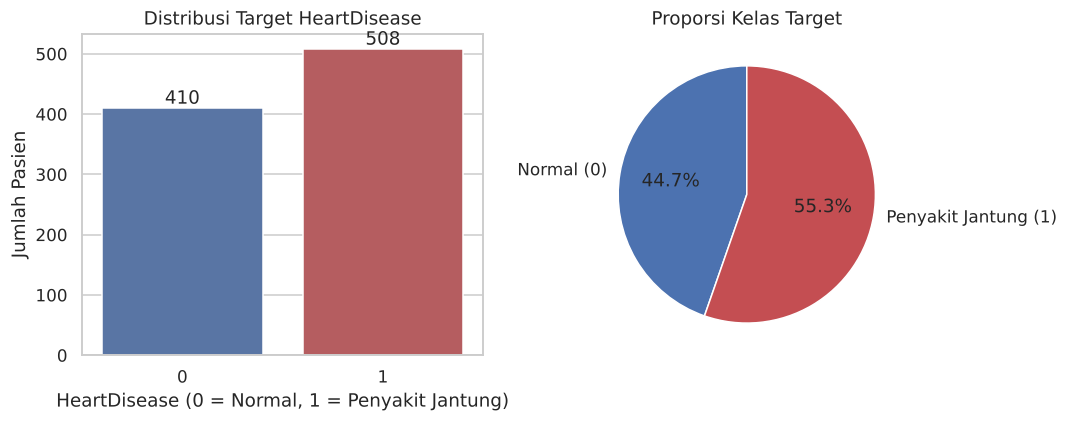

In [7]:
# Watermark NIM: 202331108
vc = df['HeartDisease'].value_counts().sort_index()
pct = (df['HeartDisease'].value_counts(normalize=True).sort_index()*100).round(2)
print(pd.DataFrame({'Jumlah': vc, 'Persen (%)': pct}))
HASIL['target'] = {'kelas0': int(vc[0]), 'kelas1': int(vc[1]), 'pct0': float(pct[0]), 'pct1': float(pct[1])}

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='HeartDisease', data=df, ax=ax[0], palette=['#4C72B0', '#C44E52'])
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax[0].set_title('Distribusi Target HeartDisease')
ax[0].set_xlabel('HeartDisease (0 = Normal, 1 = Penyakit Jantung)'); ax[0].set_ylabel('Jumlah Pasien')
ax[1].pie(vc, labels=['Normal (0)', 'Penyakit Jantung (1)'], autopct='%1.1f%%', colors=['#4C72B0', '#C44E52'], startangle=90)
ax[1].set_title('Proporsi Kelas Target')
simpan('01_target')


### 4.3 Distribusi Fitur Numerik

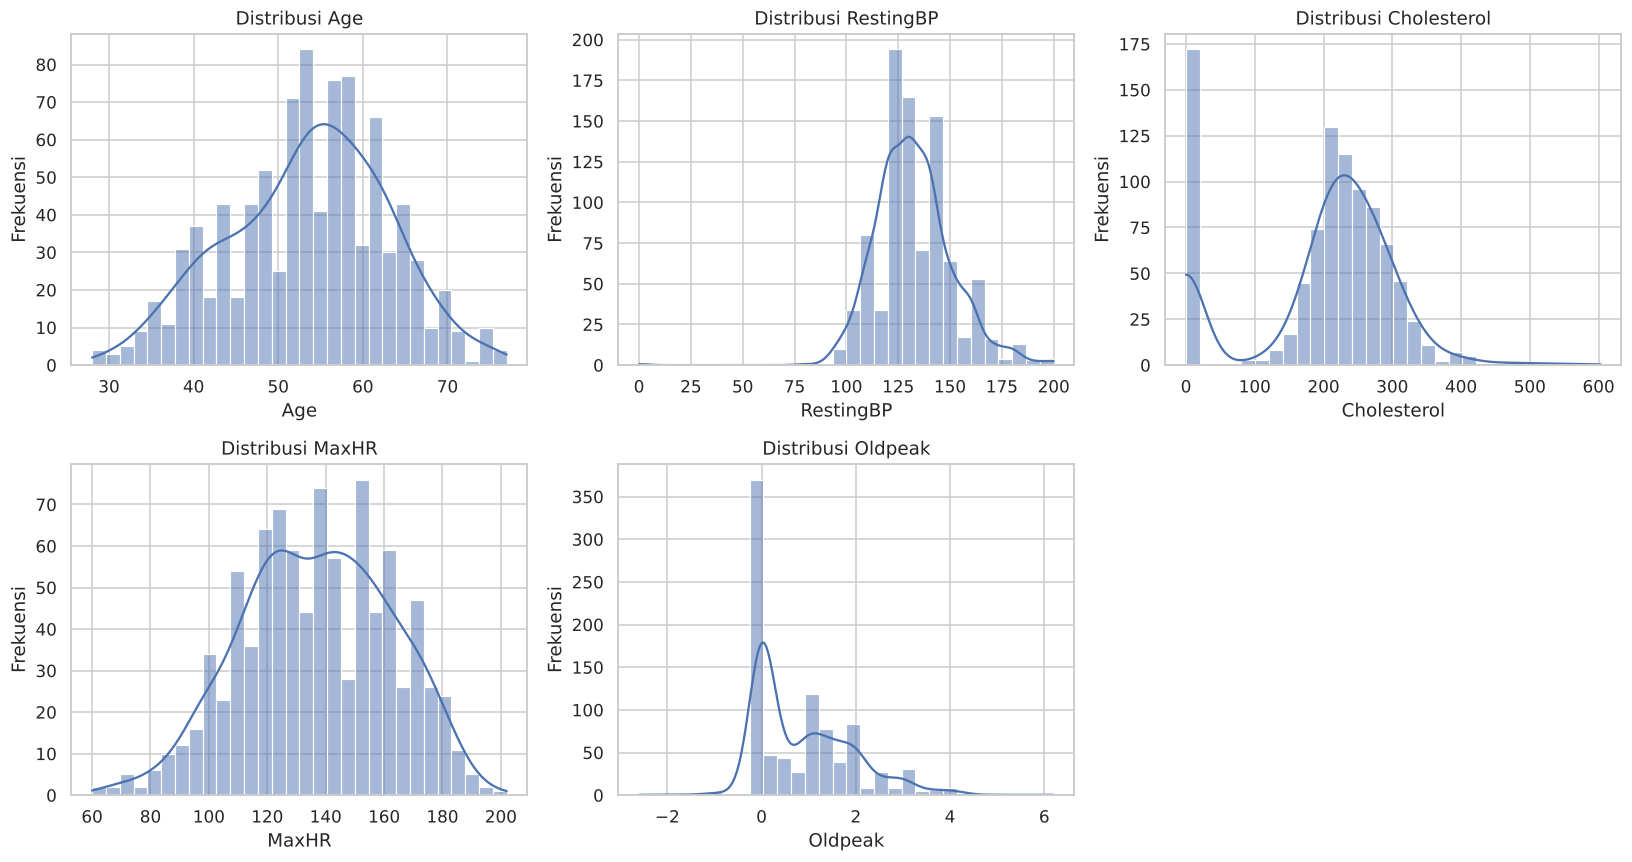

Skewness:
Age           -0.196
RestingBP      0.180
Cholesterol   -0.610
MaxHR         -0.144
Oldpeak        1.023
dtype: float64


In [8]:
# Watermark NIM: 202331108
num_cols_eda = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols_eda):
    sns.histplot(df[c], kde=True, ax=ax, color='#4C72B0', bins=30)
    ax.set_title(f'Distribusi {c}'); ax.set_xlabel(c); ax.set_ylabel('Frekuensi')
axes[1, 2].axis('off')
simpan('02_hist_numerik')
print('Skewness:'); print(df[num_cols_eda].skew().round(3))


### 4.4 Distribusi Fitur Kategorikal

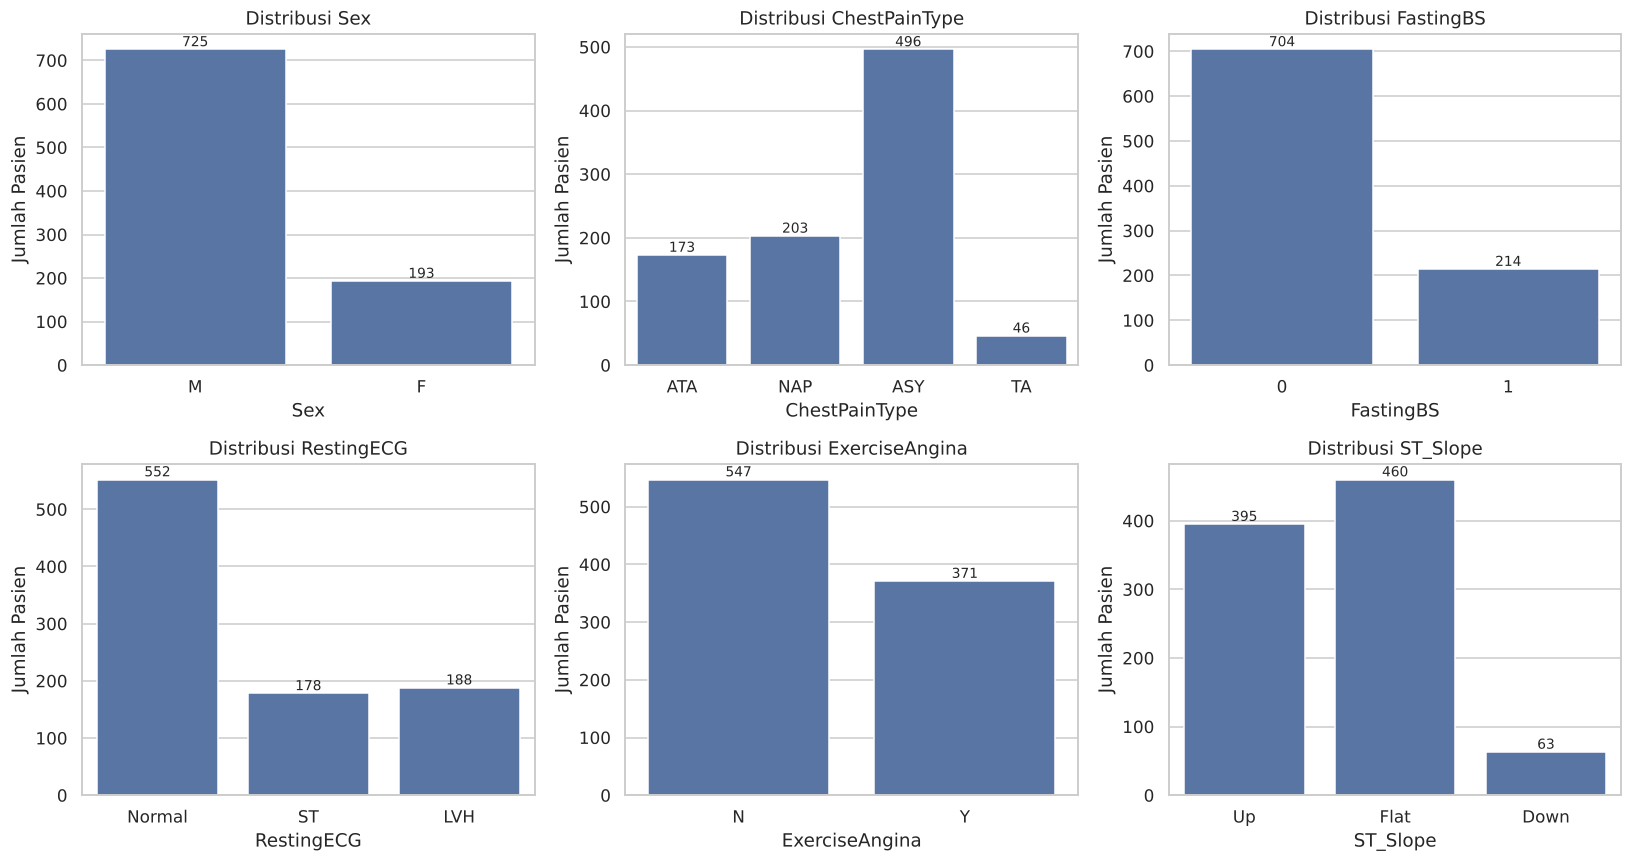

In [9]:
# Watermark NIM: 202331108
cat_cols_eda = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_cols_eda):
    sns.countplot(x=c, data=df, ax=ax, color='#4C72B0')
    ax.set_title(f'Distribusi {c}'); ax.set_xlabel(c); ax.set_ylabel('Jumlah Pasien')
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
simpan('03_count_kategorikal')


### 4.5 Hubungan Fitur dengan Target

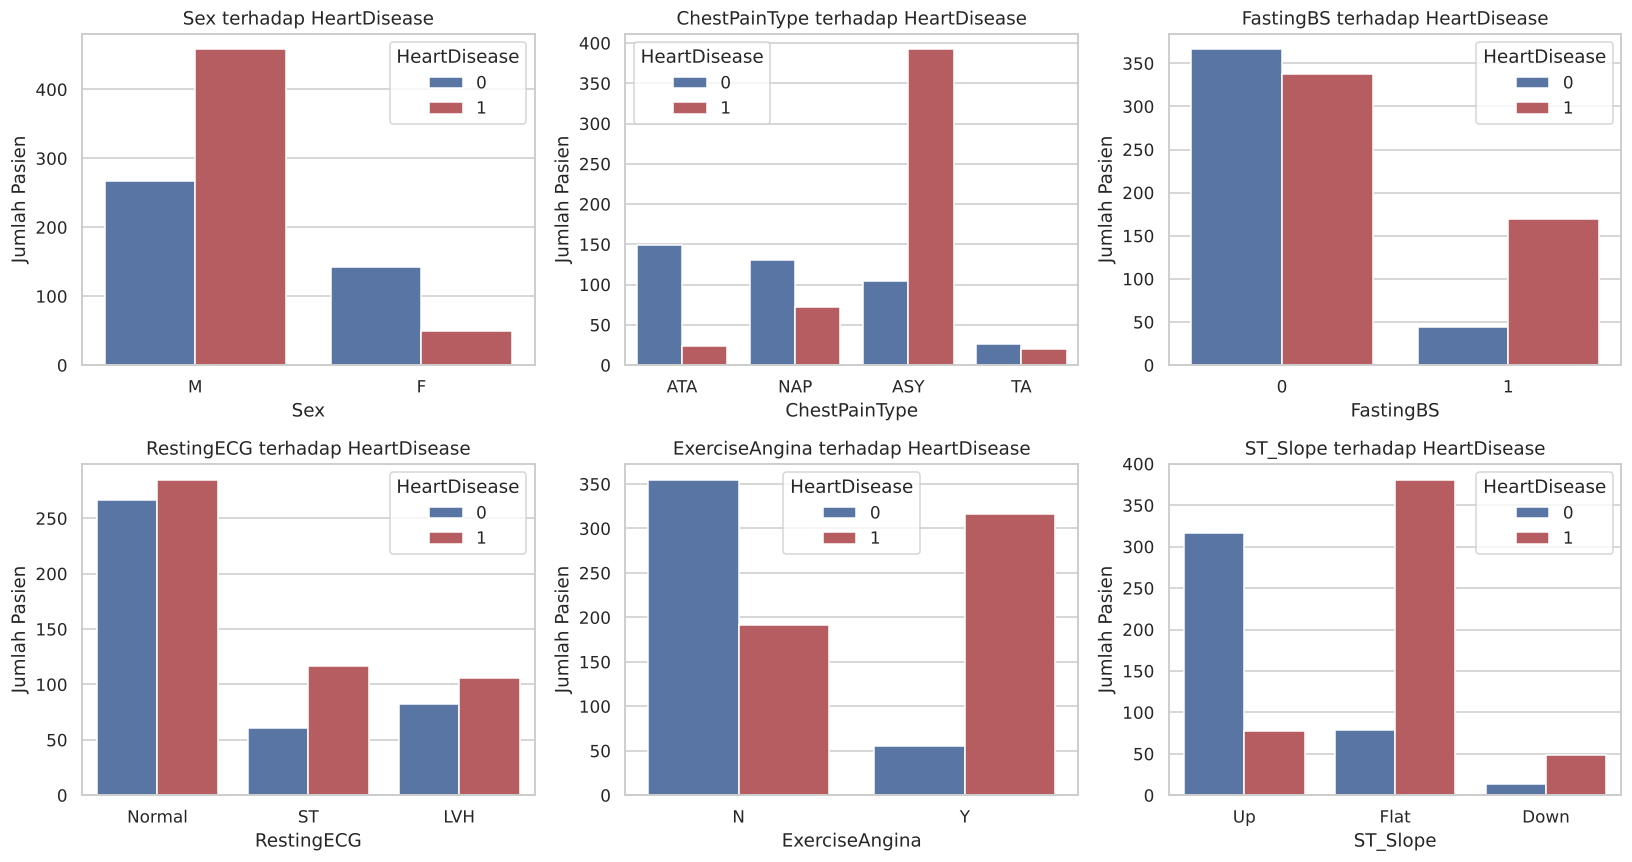

Persentase pasien berpenyakit jantung per kategori (%):

Sex
F    25.9
M    63.2

ChestPainType
ASY    79.0
ATA    13.9
NAP    35.5
TA     43.5

FastingBS
0    48.0
1    79.4

RestingECG
LVH       56.4
Normal    51.6
ST        65.7

ExerciseAngina
N    35.1
Y    85.2

ST_Slope
Down    77.8
Flat    82.8
Up      19.7


In [10]:
# Watermark NIM: 202331108
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cat_cols_eda):
    sns.countplot(x=c, hue='HeartDisease', data=df, ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_title(f'{c} terhadap HeartDisease'); ax.set_xlabel(c); ax.set_ylabel('Jumlah Pasien')
    ax.legend(title='HeartDisease')
simpan('04_kategorikal_vs_target')

print('Persentase pasien berpenyakit jantung per kategori (%):')
rate = {}
for c in cat_cols_eda:
    r = (df.groupby(c)['HeartDisease'].mean()*100).round(1)
    rate[c] = r.to_dict(); print(f'\n{c}\n{r.rename_axis(None).to_string()}')
HASIL['rate_kategori'] = {k: {str(a): b for a, b in v.items()} for k, v in rate.items()}


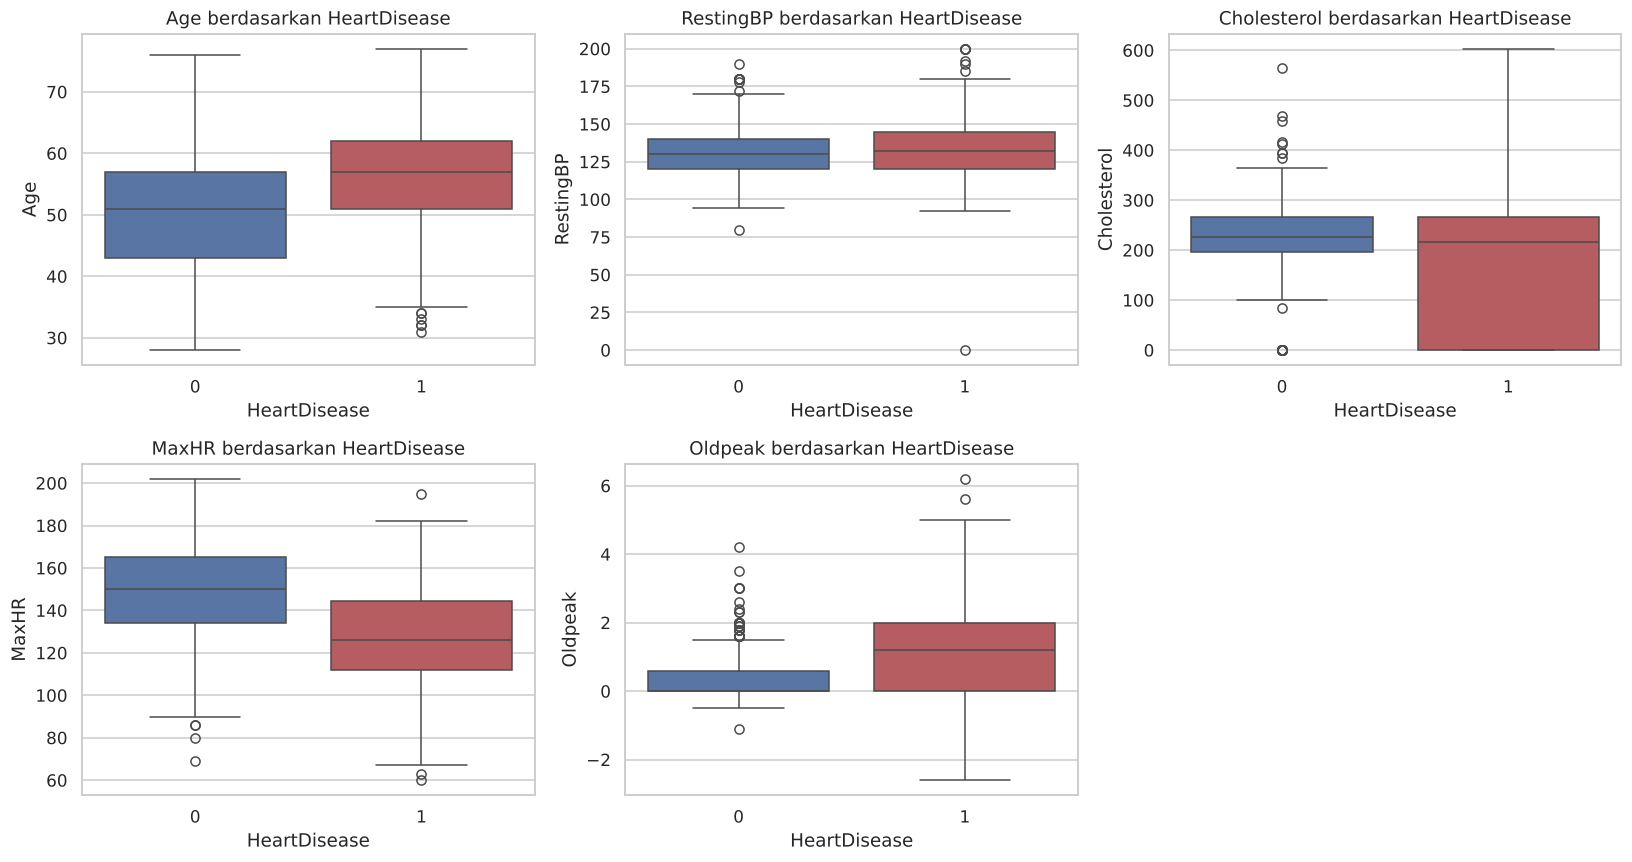

Rata-rata fitur numerik per kelas target:


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
HeartDisease,,,,,
0,50.55,130.18,227.12,148.15,0.41
1,55.90,134.19,175.94,127.66,1.27



Jumlah pasien dengan Cholesterol = 0 per kelas target:
HeartDisease        0    1
Cholesterol == 0          
False             390  356
True               20  152

Rata-rata Cholesterol per kelas (tanpa nilai 0):
HeartDisease
0    238.77
1    251.06
Name: Cholesterol, dtype: float64


In [11]:
# Watermark NIM: 202331108
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols_eda):
    sns.boxplot(x='HeartDisease', y=c, data=df, ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_title(f'{c} berdasarkan HeartDisease'); ax.set_xlabel('HeartDisease'); ax.set_ylabel(c)
axes[1, 2].axis('off')
simpan('05_boxplot_numerik_vs_target')
print('Rata-rata fitur numerik per kelas target:')
display(df.groupby('HeartDisease')[num_cols_eda].mean().round(2))

# Cek pengaruh nilai Cholesterol = 0 terhadap rata-rata
print('\nJumlah pasien dengan Cholesterol = 0 per kelas target:')
print(pd.crosstab(df['Cholesterol'] == 0, df['HeartDisease'], rownames=['Cholesterol == 0'], colnames=['HeartDisease']))
print('\nRata-rata Cholesterol per kelas (tanpa nilai 0):')
print(df[df['Cholesterol'] > 0].groupby('HeartDisease')['Cholesterol'].mean().round(2))


### 4.6 Korelasi Antar Fitur (Heatmap)

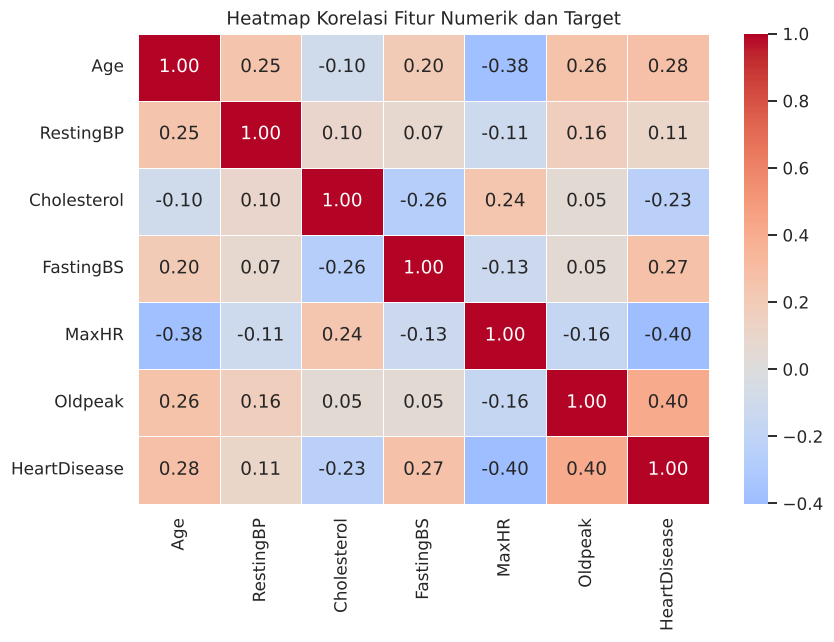

Korelasi terhadap HeartDisease (terurut):
Oldpeak        0.404
Age            0.282
FastingBS      0.267
RestingBP      0.108
Cholesterol   -0.233
MaxHR         -0.400
Name: HeartDisease, dtype: float64


In [12]:
# Watermark NIM: 202331108
corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Heatmap Korelasi Fitur Numerik dan Target')
simpan('06_heatmap_korelasi')
print('Korelasi terhadap HeartDisease (terurut):')
print(corr['HeartDisease'].drop('HeartDisease').sort_values(ascending=False).round(3))


### 4.7 Deteksi Outlier (metode IQR)

In [13]:
# Watermark NIM: 202331108
rows = []
for c in num_cols_eda:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append([c, round(lo, 2), round(hi, 2), int(((df[c] < lo) | (df[c] > hi)).sum())])
outlier = pd.DataFrame(rows, columns=['Fitur', 'Batas Bawah', 'Batas Atas', 'Jumlah Outlier'])
display(outlier)
HASIL['outlier'] = {r[0]: r[3] for r in rows}


,Fitur,Batas Bawah,Batas Atas,Jumlah Outlier
0,Age,27.50,79.50,0
1,RestingBP,90.00,170.00,28
2,Cholesterol,32.62,407.62,183
3,MaxHR,66.00,210.00,2
4,Oldpeak,-2.25,3.75,16


## 5. Data Preprocessing
Keputusan preprocessing yang diambil berdasarkan temuan EDA:

1. **Nilai 0 pada `Cholesterol` dan `RestingBP` tidak wajar secara medis** (kadar kolesterol dan tekanan darah istirahat tidak mungkin 0). Nilai ini diperlakukan sebagai *missing value* lalu diimputasi dengan **median**. Median dipilih karena tahan terhadap outlier. Imputasi dilakukan di dalam *pipeline* dan hanya dipelajari dari data training (mencegah *data leakage*).
2. **Outlier lain dipertahankan** karena masih berada dalam rentang klinis yang mungkin (misalnya `Oldpeak` tinggi dan `Oldpeak` negatif), dan menghapusnya berisiko membuang pasien berisiko tinggi.
3. **Tidak ada duplikat** sehingga tidak ada baris yang dihapus.
4. **Encoding** fitur kategorikal dengan **One-Hot Encoding** (tidak ada urutan alami pada `ChestPainType`, `RestingECG`, `ST_Slope`; fitur biner `Sex` dan `ExerciseAngina` memakai `drop='if_binary'`).
5. **Standardisasi (Z-score) hanya untuk KNN** karena KNN berbasis jarak. **Decision Tree tidak distandardisasi** karena pemisahan node berbasis ambang batas (threshold) sehingga tidak dipengaruhi skala.
6. **Split 80:20** dengan `stratify=y` dan `random_state=42`. Split dilakukan **sebelum** imputasi, encoding, dan scaling.

In [14]:
# Watermark NIM: 202331108
# Tandai nilai tidak wajar sebagai missing (NaN)
data = df.copy()
data[['RestingBP', 'Cholesterol']] = data[['RestingBP', 'Cholesterol']].replace(0, np.nan)
print('Missing setelah penandaan nilai 0:'); print(data.isnull().sum()[lambda s: s > 0])

# Fitur (X) dan target (y)
X = data.drop(columns='HeartDisease')
y = data['HeartDisease']

# Identifikasi kolom
kolom_numerik = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
kolom_kategorikal = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
kolom_biner_numerik = ['FastingBS']   # sudah 0/1, dibiarkan apa adanya
print('\nKolom numerik     :', kolom_numerik)
print('Kolom kategorikal :', kolom_kategorikal)
print('Kolom biner (0/1) :', kolom_biner_numerik)
print('Shape X:', X.shape, '| Shape y:', y.shape)


Missing setelah penandaan nilai 0:
RestingBP        1
Cholesterol    172
dtype: int64

Kolom numerik     : ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Kolom kategorikal : ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Kolom biner (0/1) : ['FastingBS']
Shape X: (918, 11) | Shape y: (918,)


In [15]:
# Watermark NIM: 202331108
# Train-test split 80:20, stratified
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('\nProporsi kelas y_train (%):'); print((y_train.value_counts(normalize=True).sort_index()*100).round(2).to_string())
print('\nProporsi kelas y_test (%):'); print((y_test.value_counts(normalize=True).sort_index()*100).round(2).to_string())
HASIL['split'] = {'train': int(len(X_train)), 'test': int(len(X_test)),
                  'train_pos_pct': float(round(y_train.mean()*100, 2)), 'test_pos_pct': float(round(y_test.mean()*100, 2))}


X_train: (734, 11) | X_test: (184, 11)

Proporsi kelas y_train (%):
HeartDisease
0    44.69
1    55.31

Proporsi kelas y_test (%):
HeartDisease
0    44.57
1    55.43


In [16]:
# Watermark NIM: 202331108
# Preprocessor Decision Tree: imputasi median + One-Hot (TANPA scaling)
pre_dt = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), kolom_numerik),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), kolom_kategorikal),
    ('bin', 'passthrough', kolom_biner_numerik)])

# Preprocessor KNN: imputasi median + StandardScaler + One-Hot
pre_knn = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), kolom_numerik),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), kolom_kategorikal),
    ('bin', 'passthrough', kolom_biner_numerik)])

# Demonstrasi: fit hanya pada data training
Xtr_knn = pre_knn.fit_transform(X_train)
Xte_knn = pre_knn.transform(X_test)
nama_fitur = list(pre_knn.get_feature_names_out())
print('Jumlah fitur setelah encoding:', len(nama_fitur))
print(nama_fitur)
print('\nRata-rata & std fitur numerik (TRAIN, setelah standardisasi):')
print(pd.DataFrame(Xtr_knn[:, :5], columns=kolom_numerik).agg(['mean', 'std']).round(3))
print('\nRata-rata fitur numerik (TEST, memakai statistik train):')
print(pd.DataFrame(Xte_knn[:, :5], columns=kolom_numerik).mean().round(3).to_string())
HASIL['prep'] = {'n_fitur': len(nama_fitur), 'nama_fitur': [n.split('__')[1] for n in nama_fitur],
                 'median_chol_train': float(X_train['Cholesterol'].median()), 'median_bp_train': float(X_train['RestingBP'].median())}


Jumlah fitur setelah encoding: 18
['num__Age', 'num__RestingBP', 'num__Cholesterol', 'num__MaxHR', 'num__Oldpeak', 'cat__Sex_M', 'cat__ChestPainType_ASY', 'cat__ChestPainType_ATA', 'cat__ChestPainType_NAP', 'cat__ChestPainType_TA', 'cat__RestingECG_LVH', 'cat__RestingECG_Normal', 'cat__RestingECG_ST', 'cat__ExerciseAngina_Y', 'cat__ST_Slope_Down', 'cat__ST_Slope_Flat', 'cat__ST_Slope_Up', 'bin__FastingBS']

Rata-rata & std fitur numerik (TRAIN, setelah standardisasi):
        Age  RestingBP  Cholesterol  MaxHR  Oldpeak
mean  0.000     -0.000        0.000 -0.000    0.000
std   1.001      1.001        1.001  1.001    1.001

Rata-rata fitur numerik (TEST, memakai statistik train):
Age           -0.179
RestingBP     -0.093
Cholesterol   -0.153
MaxHR          0.083
Oldpeak        0.105


## 6. Model Decision Tree
Decision Tree membagi data secara rekursif berdasarkan fitur dan ambang batas yang paling menurunkan impurity (Gini atau Entropy) sampai kriteria berhenti terpenuhi. Pohon tanpa batas kedalaman cenderung *overfitting*, sehingga hiperparameter `criterion`, `max_depth`, dan `min_samples_leaf` dicari dengan **GridSearchCV (5-fold stratified) pada data training saja**. Data testing tidak disentuh selama pemilihan parameter.

In [17]:
# Watermark NIM: 202331108
# Baseline: pohon tanpa pembatasan (untuk melihat overfitting)
base_dt = Pipeline([('pre', pre_dt), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(X_train, y_train)
print('Baseline DT tanpa batasan -> akurasi train: %.4f | akurasi test: %.4f' % (
    base_dt.score(X_train, y_train), base_dt.score(X_test, y_test)))
print('Kedalaman pohon baseline:', base_dt.named_steps['clf'].get_depth())
HASIL['dt_baseline'] = {'train': float(base_dt.score(X_train, y_train)), 'test': float(base_dt.score(X_test, y_test)),
                        'depth': int(base_dt.named_steps['clf'].get_depth())}


Baseline DT tanpa batasan -> akurasi train: 1.0000 | akurasi test: 0.7500
Kedalaman pohon baseline: 12


In [18]:
# Watermark NIM: 202331108
pipe_dt = Pipeline([('pre', pre_dt), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))])
param_dt = {'clf__criterion': ['gini', 'entropy'],
            'clf__max_depth': [2, 3, 4, 5, 6, 7, 8, 10, None],
            'clf__min_samples_leaf': [1, 2, 5, 10, 20]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_dt = GridSearchCV(pipe_dt, param_dt, cv=cv, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
print('Parameter terbaik   :', gs_dt.best_params_)
print('Akurasi CV (train)  : %.4f' % gs_dt.best_score_)
dt_model = gs_dt.best_estimator_
HASIL['dt_params'] = {k.replace('clf__', ''): (None if v is None else (int(v) if isinstance(v, (int, np.integer)) else v))
                      for k, v in gs_dt.best_params_.items()}
HASIL['dt_cv'] = float(gs_dt.best_score_)


Parameter terbaik   : {'clf__criterion': 'gini', 'clf__max_depth': 4, 'clf__min_samples_leaf': 10}
Akurasi CV (train)  : 0.8406


### 6.1 Evaluasi Decision Tree (data testing)

Accuracy  : 0.7935
Precision : 0.8200
Recall    : 0.8039
F1-score  : 0.8119
ROC-AUC   : 0.8544

Classification Report:
                      precision    recall  f1-score   support

          Normal (0)     0.7619    0.7805    0.7711        82
Penyakit Jantung (1)     0.8200    0.8039    0.8119       102

            accuracy                         0.7935       184
           macro avg     0.7910    0.7922    0.7915       184
        weighted avg     0.7941    0.7935    0.7937       184

TN=64  FP=18  FN=20  TP=82


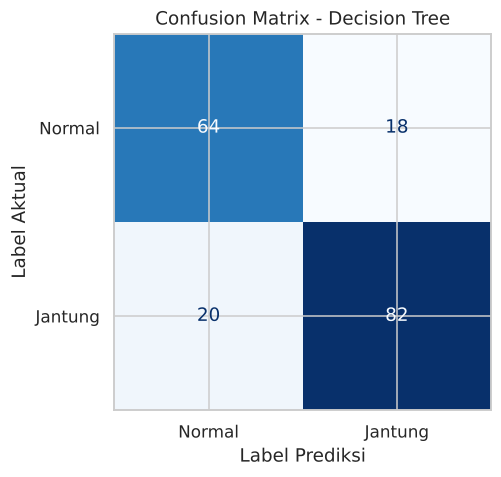

In [19]:
# Watermark NIM: 202331108
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]
acc_dt = accuracy_score(y_test, y_pred_dt); pre_dt_s = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt); f1_dt = f1_score(y_test, y_pred_dt); auc_dt = roc_auc_score(y_test, y_prob_dt)
print(f'Accuracy  : {acc_dt:.4f}\nPrecision : {pre_dt_s:.4f}\nRecall    : {rec_dt:.4f}\nF1-score  : {f1_dt:.4f}\nROC-AUC   : {auc_dt:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_dt, target_names=['Normal (0)', 'Penyakit Jantung (1)'], digits=4))
cm_dt = confusion_matrix(y_test, y_pred_dt)
tn, fp, fn, tp = cm_dt.ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
HASIL['dt'] = {'accuracy': acc_dt, 'precision': pre_dt_s, 'recall': rec_dt, 'f1': f1_dt, 'auc': auc_dt,
               'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
               'train_acc': float(dt_model.score(X_train, y_train)), 'depth': int(dt_model.named_steps['clf'].get_depth()),
               'leaves': int(dt_model.named_steps['clf'].get_n_leaves())}

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm_dt, display_labels=['Normal', 'Jantung']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix - Decision Tree'); ax.set_xlabel('Label Prediksi'); ax.set_ylabel('Label Aktual')
simpan('07_cm_decision_tree')


### 6.2 Visualisasi Pohon Keputusan dan Pentingnya Fitur

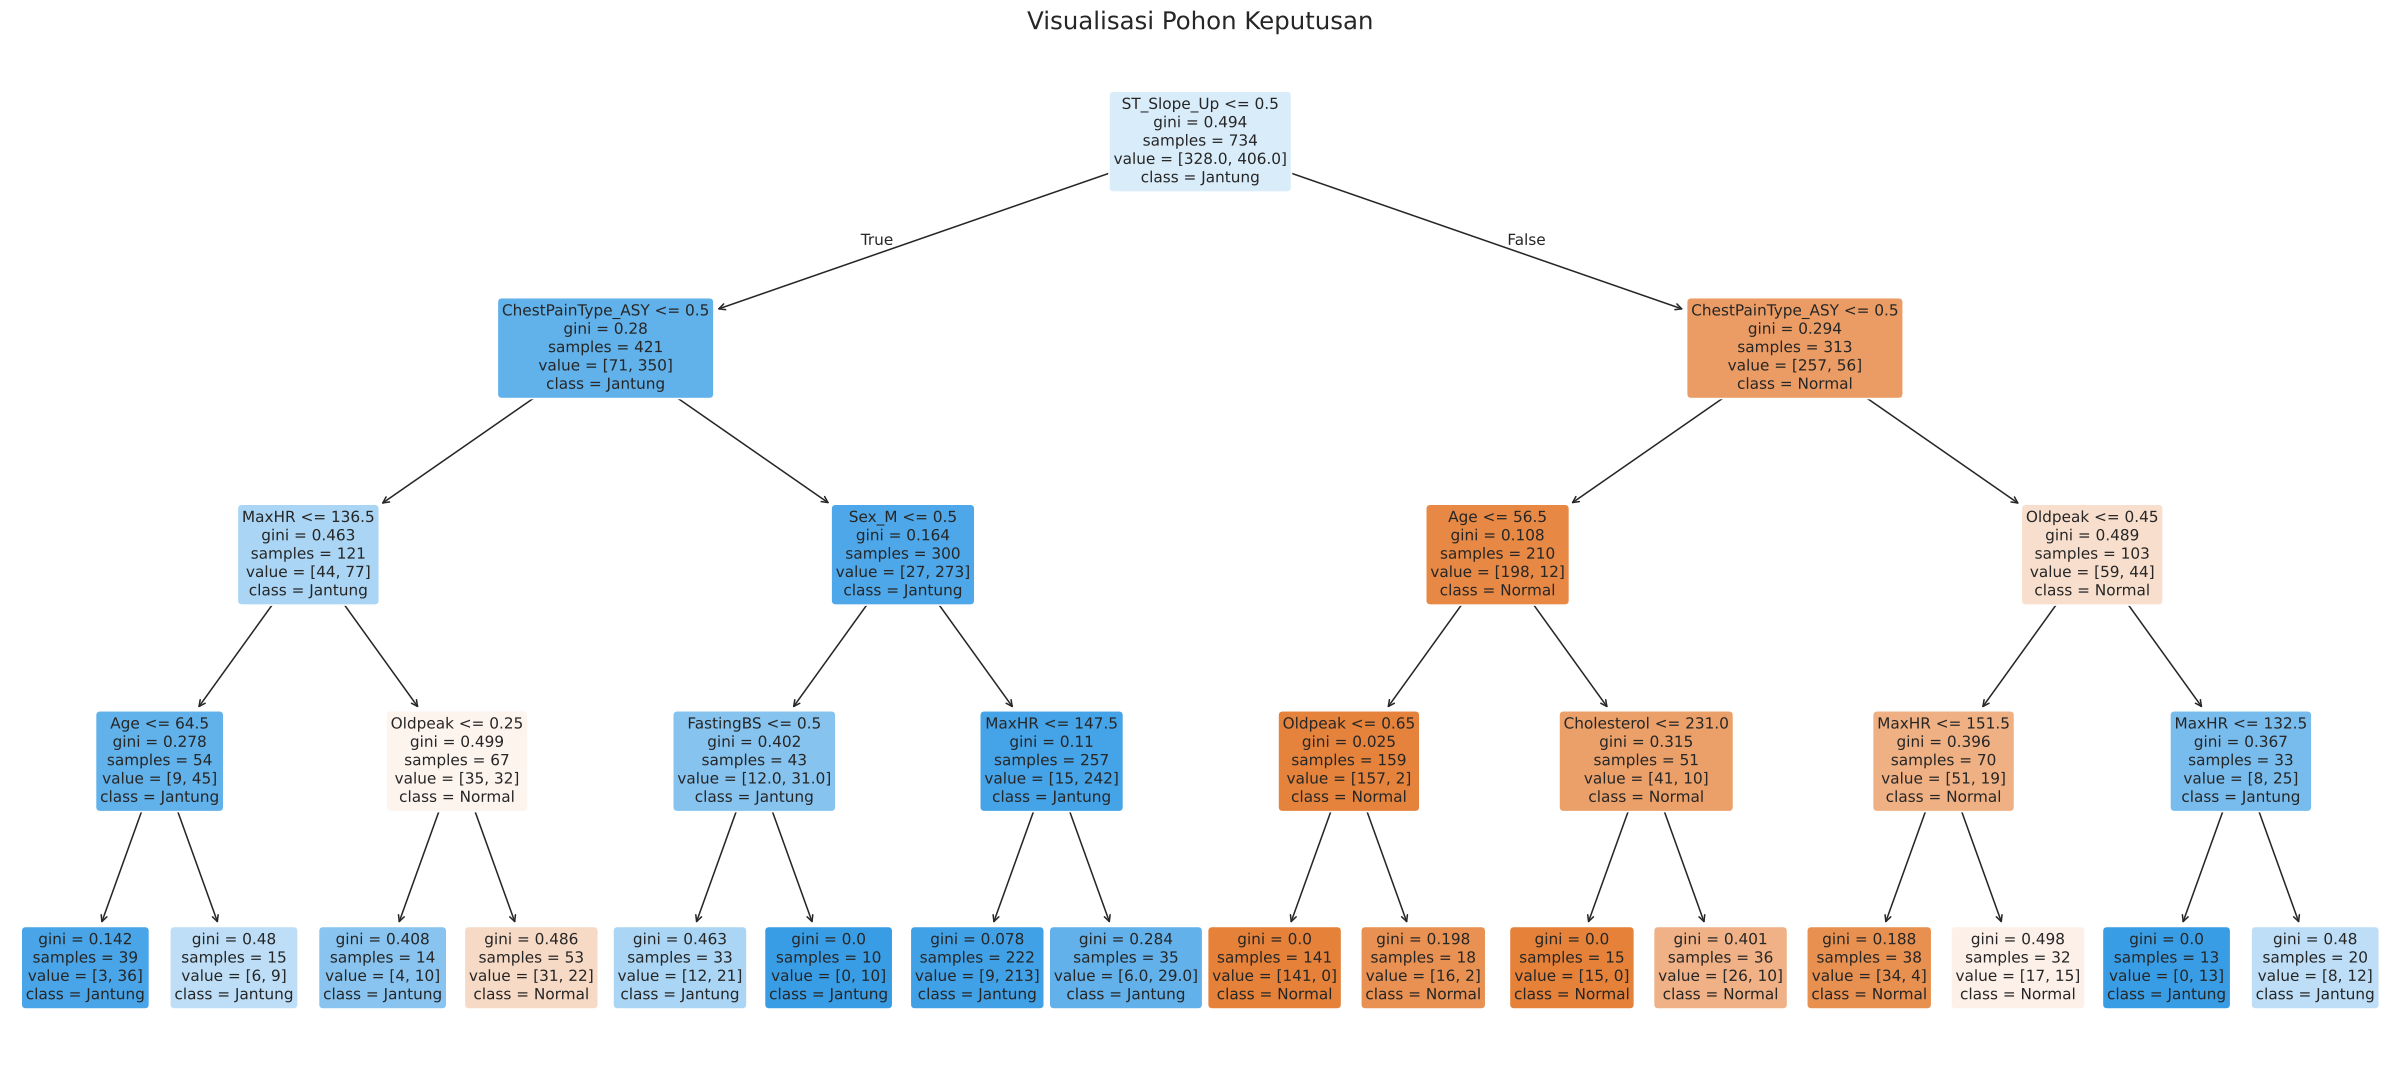

|--- ST_Slope_Up <= 0.50
|   |--- ChestPainType_ASY <= 0.50
|   |   |--- MaxHR <= 136.50
|   |   |   |--- Age <= 64.50
|   |   |   |   |--- class: 1
|   |   |   |--- Age >  64.50
|   |   |   |   |--- class: 1
|   |   |--- MaxHR >  136.50
|   |   |   |--- Oldpeak <= 0.25
|   |   |   |   |--- class: 1
|   |   |   |--- Oldpeak >  0.25
|   |   |   |   |--- class: 0
|   |--- ChestPainType_ASY >  0.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- FastingBS <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- FastingBS >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- MaxHR <= 147.50
|   |   |   |   |--- class: 1
|   |   |   |--- MaxHR >  147.50
|   |   |   |   |--- class: 1
|--- ST_Slope_Up >  0.50
|   |--- ChestPainType_ASY <= 0.50
|   |   |--- Age <= 56.50
|   |   |   |--- Oldpeak <= 0.65
|   |   |   |   |--- class: 0
|   |   |   |--- Oldpeak >  0.65
|   |   |   |   |--- class: 0
|   |   |--- Age >  56.50
|   |   |   |--- Cholesterol <= 231.00
|   |   |   | 

In [20]:
# Watermark NIM: 202331108
clf_dt = dt_model.named_steps['clf']
fitur_dt = [n.split('__')[1] for n in dt_model.named_steps['pre'].get_feature_names_out()]
depth_plot = None if clf_dt.get_depth() <= 4 else 3
plt.figure(figsize=(22, 10))
plot_tree(clf_dt, feature_names=fitur_dt, class_names=['Normal', 'Jantung'], filled=True, rounded=True,
          fontsize=10, max_depth=depth_plot, proportion=False)
plt.title('Visualisasi Pohon Keputusan' + (' (ditampilkan sampai kedalaman 3)' if depth_plot else ''), fontsize=16)
simpan('08_plot_tree')
print(export_text(clf_dt, feature_names=fitur_dt, max_depth=3))


ST_Slope_Up          0.6778
ChestPainType_ASY    0.1412
MaxHR                0.0697
Oldpeak              0.0576
Age                  0.0216
Sex_M                0.0159
FastingBS            0.0090
Cholesterol          0.0072
RestingBP            0.0000
ChestPainType_ATA    0.0000
dtype: float64


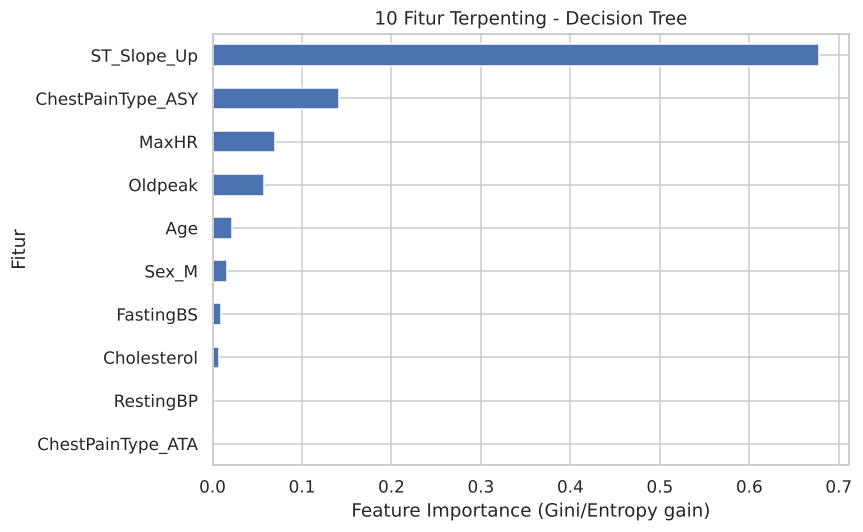

In [21]:
# Watermark NIM: 202331108
imp = pd.Series(clf_dt.feature_importances_, index=fitur_dt).sort_values(ascending=False)
print(imp.round(4).head(10))
HASIL['dt_importance'] = {k: float(v) for k, v in imp.head(6).items()}
plt.figure(figsize=(8, 5))
imp.head(10).sort_values().plot(kind='barh', color='#4C72B0')
plt.title('10 Fitur Terpenting - Decision Tree'); plt.xlabel('Feature Importance (Gini/Entropy gain)'); plt.ylabel('Fitur')
simpan('09_importance_dt')


## 7. Model K-Nearest Neighbors (KNN)
KNN mengklasifikasikan data baru berdasarkan mayoritas kelas dari *K* tetangga terdekat (jarak Euclidean). Karena berbasis jarak, fitur harus distandardisasi (sudah ada di `pre_knn`). Nilai K diuji dari 1 sampai 30; **pemilihan K memakai akurasi cross-validation 5-fold pada data training**. Akurasi pada data testing ikut digambar hanya untuk ilustrasi dan tidak dipakai untuk memilih K.

K,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
Akurasi CV (train),0.7916,0.7820,0.8175,0.8189,0.8338,0.8338,0.8447,0.8366,0.8420,0.8502,...,0.8461,0.8461,0.8502,0.8447,0.8434,0.8406,0.8420,0.8406,0.8393,0.8406
Akurasi Train,1.0000,0.8951,0.9046,0.8828,0.8719,0.8678,0.8678,0.8692,0.8665,0.8678,...,0.8610,0.8610,0.8569,0.8597,0.8529,0.8542,0.8529,0.8529,0.8515,0.8488
Akurasi Test,0.8098,0.7772,0.8533,0.8207,0.8424,0.8641,0.8750,0.8750,0.8750,0.8750,...,0.8913,0.8804,0.8913,0.8804,0.8804,0.8804,0.8967,0.8804,0.8804,0.8696


K terbaik (akurasi CV tertinggi): 10 | akurasi CV = 0.8502


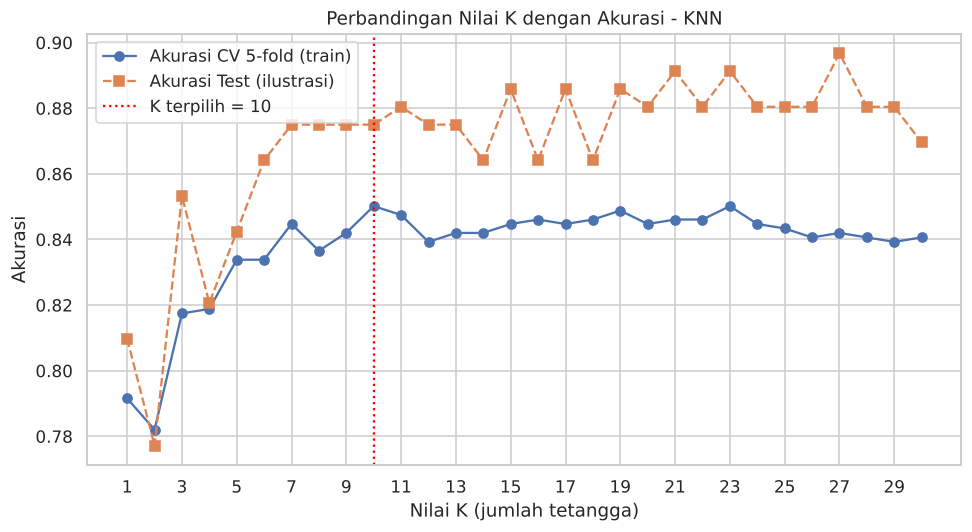

In [22]:
# Watermark NIM: 202331108
hasil_k = []
for k in range(1, 31):
    pipe_k = Pipeline([('pre', pre_knn), ('clf', KNeighborsClassifier(n_neighbors=k))])
    cv_acc = cross_val_score(pipe_k, X_train, y_train, cv=cv, scoring='accuracy').mean()
    pipe_k.fit(X_train, y_train)
    hasil_k.append([k, cv_acc, pipe_k.score(X_train, y_train), pipe_k.score(X_test, y_test)])
tabel_k = pd.DataFrame(hasil_k, columns=['K', 'Akurasi CV (train)', 'Akurasi Train', 'Akurasi Test'])
display(tabel_k.round(4).set_index('K').T)

k_terbaik = int(tabel_k.loc[tabel_k['Akurasi CV (train)'].idxmax(), 'K'])
print('K terbaik (akurasi CV tertinggi):', k_terbaik, '| akurasi CV = %.4f' % tabel_k['Akurasi CV (train)'].max())
HASIL['knn_k'] = {'k_terbaik': k_terbaik, 'cv_terbaik': float(tabel_k['Akurasi CV (train)'].max()),
                  'tabel': tabel_k.round(4).to_dict(orient='list')}

plt.figure(figsize=(9, 5))
plt.plot(tabel_k['K'], tabel_k['Akurasi CV (train)'], marker='o', label='Akurasi CV 5-fold (train)')
plt.plot(tabel_k['K'], tabel_k['Akurasi Test'], marker='s', linestyle='--', label='Akurasi Test (ilustrasi)')
plt.axvline(k_terbaik, color='red', linestyle=':', label=f'K terpilih = {k_terbaik}')
plt.title('Perbandingan Nilai K dengan Akurasi - KNN'); plt.xlabel('Nilai K (jumlah tetangga)'); plt.ylabel('Akurasi')
plt.xticks(range(1, 31, 2)); plt.legend()
simpan('10_k_vs_akurasi')


### 7.1 Evaluasi KNN (data testing)

K = 10
Accuracy  : 0.8750
Precision : 0.9247
Recall    : 0.8431
F1-score  : 0.8821
ROC-AUC   : 0.9356

Classification Report:
                      precision    recall  f1-score   support

          Normal (0)     0.8242    0.9146    0.8671        82
Penyakit Jantung (1)     0.9247    0.8431    0.8821       102

            accuracy                         0.8750       184
           macro avg     0.8745    0.8789    0.8746       184
        weighted avg     0.8799    0.8750    0.8754       184

TN=75  FP=7  FN=16  TP=86


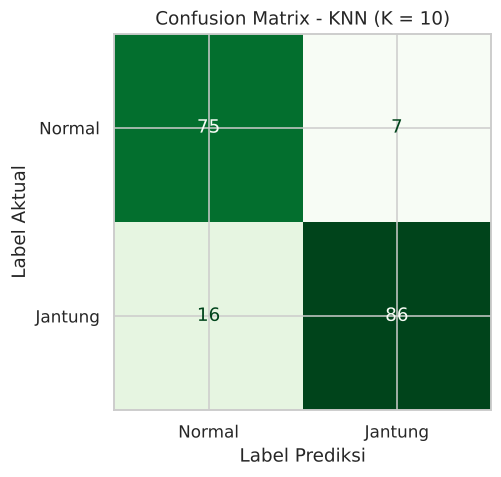

In [23]:
# Watermark NIM: 202331108
knn_model = Pipeline([('pre', pre_knn), ('clf', KNeighborsClassifier(n_neighbors=k_terbaik))]).fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]
acc_knn = accuracy_score(y_test, y_pred_knn); pre_knn_s = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn); f1_knn = f1_score(y_test, y_pred_knn); auc_knn = roc_auc_score(y_test, y_prob_knn)
print(f'K = {k_terbaik}')
print(f'Accuracy  : {acc_knn:.4f}\nPrecision : {pre_knn_s:.4f}\nRecall    : {rec_knn:.4f}\nF1-score  : {f1_knn:.4f}\nROC-AUC   : {auc_knn:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_knn, target_names=['Normal (0)', 'Penyakit Jantung (1)'], digits=4))
cm_knn = confusion_matrix(y_test, y_pred_knn)
tn, fp, fn, tp = cm_knn.ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
HASIL['knn'] = {'k': k_terbaik, 'accuracy': acc_knn, 'precision': pre_knn_s, 'recall': rec_knn, 'f1': f1_knn, 'auc': auc_knn,
                'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp), 'train_acc': float(knn_model.score(X_train, y_train))}

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm_knn, display_labels=['Normal', 'Jantung']).plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title(f'Confusion Matrix - KNN (K = {k_terbaik})'); ax.set_xlabel('Label Prediksi'); ax.set_ylabel('Label Aktual')
simpan('11_cm_knn')


## 8. Perbandingan Decision Tree dan KNN

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Algoritma,,,,,
Decision Tree,0.7935,0.8200,0.8039,0.8119,0.8544
KNN (K=10),0.8750,0.9247,0.8431,0.8821,0.9356


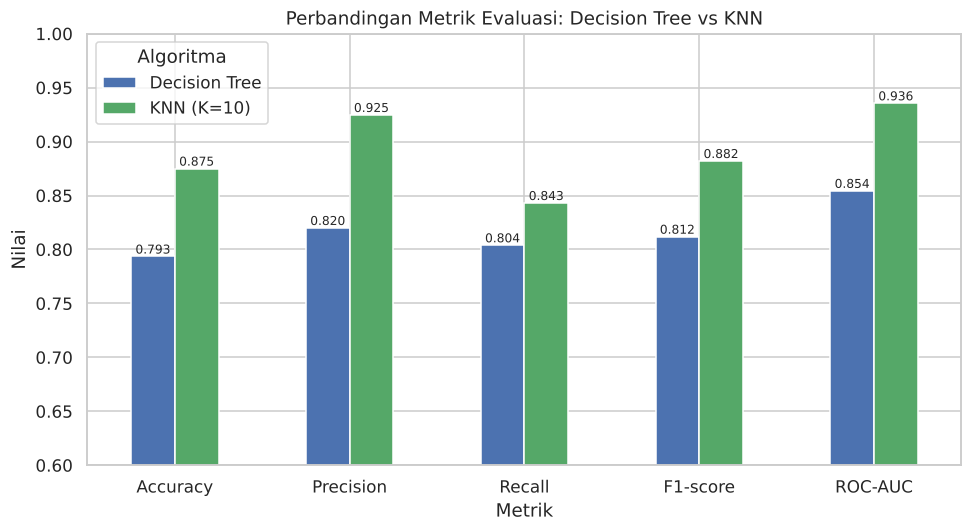

In [24]:
# Watermark NIM: 202331108
perb = pd.DataFrame({
    'Algoritma': ['Decision Tree', f'KNN (K={k_terbaik})'],
    'Accuracy': [acc_dt, acc_knn], 'Precision': [pre_dt_s, pre_knn_s],
    'Recall': [rec_dt, rec_knn], 'F1-score': [f1_dt, f1_knn], 'ROC-AUC': [auc_dt, auc_knn]}).set_index('Algoritma')
display(perb.round(4))

ax = perb[['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']].T.plot(kind='bar', figsize=(9, 5), color=['#4C72B0', '#55A868'], rot=0)
ax.set_title('Perbandingan Metrik Evaluasi: Decision Tree vs KNN'); ax.set_xlabel('Metrik'); ax.set_ylabel('Nilai')
ax.set_ylim(0.6, 1.0); ax.legend(title='Algoritma')
for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=8)
simpan('12_perbandingan_metrik')


Repeated CV (15 lipatan) Decision Tree : 0.8286 +/- 0.0240
Repeated CV (15 lipatan) KNN           : 0.8551 +/- 0.0160


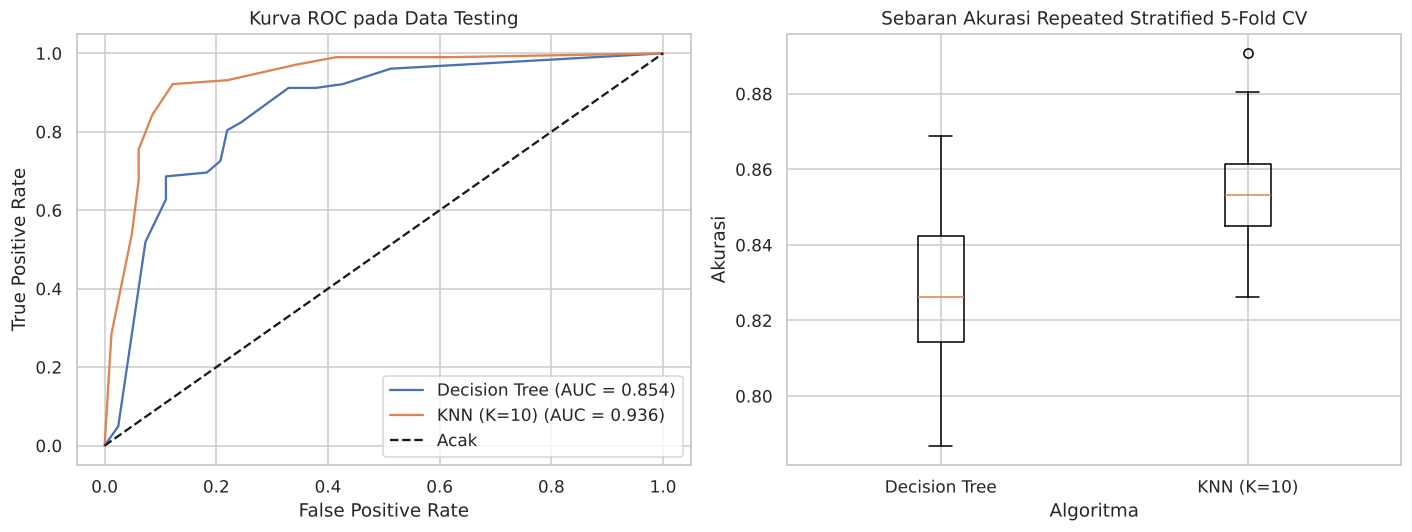

In [25]:
# Watermark NIM: 202331108
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nama, prob, auc in [('Decision Tree', y_prob_dt, auc_dt), (f'KNN (K={k_terbaik})', y_prob_knn, auc_knn)]:
    fpr, tpr, _ = roc_curve(y_test, prob); ax[0].plot(fpr, tpr, label=f'{nama} (AUC = {auc:.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='Acak'); ax[0].set_title('Kurva ROC pada Data Testing')
ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate'); ax[0].legend()

# Uji ketahanan: Repeated Stratified 5-Fold (3x) pada seluruh data memakai hiperparameter terpilih
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
dt_cv = cross_val_score(Pipeline([('pre', pre_dt), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE, **HASIL['dt_params']))]), X, y, cv=rcv)
knn_cv = cross_val_score(Pipeline([('pre', pre_knn), ('clf', KNeighborsClassifier(n_neighbors=k_terbaik))]), X, y, cv=rcv)
print(f'Repeated CV (15 lipatan) Decision Tree : {dt_cv.mean():.4f} +/- {dt_cv.std():.4f}')
print(f'Repeated CV (15 lipatan) KNN           : {knn_cv.mean():.4f} +/- {knn_cv.std():.4f}')
HASIL['rcv'] = {'dt_mean': float(dt_cv.mean()), 'dt_std': float(dt_cv.std()), 'knn_mean': float(knn_cv.mean()), 'knn_std': float(knn_cv.std())}
ax[1].boxplot([dt_cv, knn_cv])
ax[1].set_xticklabels(['Decision Tree', f'KNN (K={k_terbaik})'])
ax[1].set_title('Sebaran Akurasi Repeated Stratified 5-Fold CV'); ax[1].set_xlabel('Algoritma'); ax[1].set_ylabel('Akurasi')
simpan('13_roc_dan_rcv')


In [26]:
# Watermark NIM: 202331108
kelebihan_kekurangan = pd.DataFrame({
    'Algoritma': ['Decision Tree', 'KNN'],
    'Kelebihan': ['Mudah diinterpretasi (aturan if-then), tidak perlu scaling, menangani fitur campuran, memberi feature importance',
                  'Sederhana, tanpa proses training eksplisit, mampu menangkap batas keputusan non-linear, efektif bila fitur sudah diskalakan'],
    'Kekurangan': ['Rentan overfitting, tidak stabil terhadap perubahan data kecil, perlu pembatasan kedalaman',
                   'Sensitif terhadap skala dan fitur tidak relevan, prediksi lambat pada data besar, hasil bergantung pada K dan jarak']})
pd.set_option('display.max_colwidth', None)
display(kelebihan_kekurangan)

lebih = lambda a, b: 'Decision Tree' if a > b else ('KNN' if b > a else 'Sama')
print('Akurasi lebih tinggi   :', lebih(acc_dt, acc_knn))
print('Precision lebih baik   :', lebih(pre_dt_s, pre_knn_s))
print('Recall lebih baik      :', lebih(rec_dt, rec_knn))
print('F1-score lebih baik    :', lebih(f1_dt, f1_knn))
print('ROC-AUC lebih baik     :', lebih(auc_dt, auc_knn))
HASIL['pemenang'] = {'accuracy': lebih(acc_dt, acc_knn), 'precision': lebih(pre_dt_s, pre_knn_s), 'recall': lebih(rec_dt, rec_knn),
                     'f1': lebih(f1_dt, f1_knn), 'auc': lebih(auc_dt, auc_knn)}
with open('hasil.json', 'w') as f: json.dump(HASIL, f, indent=1, default=str)
print('\nSeluruh hasil disimpan ke hasil.json')


,Algoritma,Kelebihan,Kekurangan
0,Decision Tree,"Mudah diinterpretasi (aturan if-then), tidak perlu scaling, menangani fitur campuran, memberi feature importance","Rentan overfitting, tidak stabil terhadap perubahan data kecil, perlu pembatasan kedalaman"
1,KNN,"Sederhana, tanpa proses training eksplisit, mampu menangkap batas keputusan non-linear, efektif bila fitur sudah diskalakan","Sensitif terhadap skala dan fitur tidak relevan, prediksi lambat pada data besar, hasil bergantung pada K dan jarak"


Akurasi lebih tinggi   : KNN
Precision lebih baik   : KNN
Recall lebih baik      : KNN
F1-score lebih baik    : KNN
ROC-AUC lebih baik     : KNN

Seluruh hasil disimpan ke hasil.json


## 9. Kesimpulan Hasil Eksperimen
1. **EDA dan preprocessing.** Dataset berisi 918 pasien dan 12 kolom, tanpa missing value (NaN) dan tanpa duplikat. Target relatif seimbang (410 normal = 44,66% dan 508 penyakit jantung = 55,34%). EDA menemukan 172 nilai `Cholesterol` = 0 dan 1 nilai `RestingBP` = 0 yang tidak wajar secara medis; keduanya diubah menjadi NaN dan diimputasi median di dalam pipeline. Fitur yang paling berkaitan dengan penyakit jantung adalah `ST_Slope`, `ExerciseAngina`, `ChestPainType` (tipe ASY), `Oldpeak`, dan `MaxHR`. Data dibagi 80:20 (734 training, 184 testing) dengan `stratify=y` dan `random_state=42`.
2. **Decision Tree.** Pohon tanpa batasan mencapai akurasi training 1,000 tetapi hanya 0,750 pada testing (overfitting). Setelah tuning (`criterion='gini'`, `max_depth=4`, `min_samples_leaf=10`), akurasi testing menjadi **0,7935** dengan precision 0,8200, recall 0,8039, dan F1-score 0,8119. Fitur dengan importance tertinggi adalah `ST_Slope_Up` (0,678) dan `ChestPainType_ASY` (0,141).
3. **KNN.** Dengan standardisasi dan pemilihan K melalui cross-validation pada data training, diperoleh K = 10. Akurasi testing **0,8750** dengan precision 0,9247, recall 0,8431, dan F1-score 0,8821.
4. **Perbandingan.** KNN lebih tinggi daripada Decision Tree pada akurasi (0,8750 vs 0,7935), precision (0,9247 vs 0,8200), recall (0,8431 vs 0,8039), F1-score (0,8821 vs 0,8119), dan ROC-AUC (0,9356 vs 0,8544). Uji ketahanan Repeated Stratified 5-Fold CV (3 ulangan) juga searah: KNN 0,8551 ± 0,0160 dan Decision Tree 0,8286 ± 0,0240.
5. **Algoritma terbaik.** Berdasarkan eksperimen ini, **KNN** memberikan performa terbaik untuk memprediksi penyakit jantung pada dataset `01_heart_disease.csv`. Decision Tree tetap unggul dari sisi interpretabilitas karena menghasilkan aturan if-then yang mudah dibaca.
6. **Keterbatasan.** Hasil berasal dari satu dataset dan satu pembagian data testing (184 pasien), sehingga selisih performa perlu dibaca dengan hati-hati. Pada kasus medis, recall (mengurangi pasien sakit yang terlewat) perlu mendapat perhatian; kedua model masih menghasilkan false negative (Decision Tree 20, KNN 16).
